<a href="https://colab.research.google.com/github/vusu4242/hm2_vus_konovalenko/blob/main/01_two_stage_faster_rcnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two-stage anchor-based detector: Faster R-CNN
Setup


In [5]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [23]:
import matplotlib.pyplot as plt, matplotlib.patches as patches

In [6]:
import os
from pathlib import Path
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('hm2')

if not Path('/content/data/train').exists():
    !kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/data
    !cd /content/data && unzip -q '*.zip' && rm *.zip
else:
    print('Data is here')
ROOT = Path('/content/data')

100% 9.88G/9.88G [01:35<00:00, 111MB/s] 



In [7]:
from google.colab import drive
drive.mount('/content/drive')

PREP = Path('/content/prepared')
if not PREP.exists():
    !unzip -q /content/drive/MyDrive/hw2_prepared.zip -d /content
for split in ['train', 'val']:
    n = sum(1 for _ in (PREP / split / 'images').rglob('*.jpg'))
    print(f'{split}: {n} кадрів')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train: 4868 кадрів
val: 571 кадрів


## Dataset
Reads the preprocessed frames and YOLO labels and converts them to the torchvision format: boxes as `[x1, y1, x2, y2]` in pixels, class ids shifted by +1 (0 is reserved for background). Training augmentation: horizontal flip (p=0.5). Normalization (ImageNet mean/std) and resizing are done inside the torchvision model.

In [8]:
import random, cv2, numpy as np, torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

CLASSES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
SEED = 42

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

class DetDataset(Dataset):
    def __init__(self, split, train=False):
        self.imgs = sorted((PREP / split / 'images').rglob('*.jpg'))
        self.train = train

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        p = self.imgs[i]
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        lp = Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt')
        a = np.loadtxt(lp, ndmin=2) if lp.stat().st_size else np.zeros((0, 5))
        cls, cx, cy, w, h = a.T
        boxes = np.stack([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H], 1)
        keep = (boxes[:, 2] - boxes[:, 0] > 1) & (boxes[:, 3] - boxes[:, 1] > 1)   # прибираємо вироджені бокси
        boxes, cls = boxes[keep], cls[keep]
        if self.train and random.random() < 0.5:                                    # горизонтальний фліп
            img = img[:, ::-1].copy()
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        target = {'boxes': torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                  'labels': torch.as_tensor(cls + 1, dtype=torch.int64)}            # +1: 0 = фон
        return TF.to_tensor(img), target

def collate(batch):
    return tuple(zip(*batch))

g = torch.Generator().manual_seed(SEED)
train_ds = DetDataset('train', train=True)
train_dl = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=collate, generator=g)
print('train frames:', len(train_ds))

train frames: 4868


#### Check: one training batch with boxes

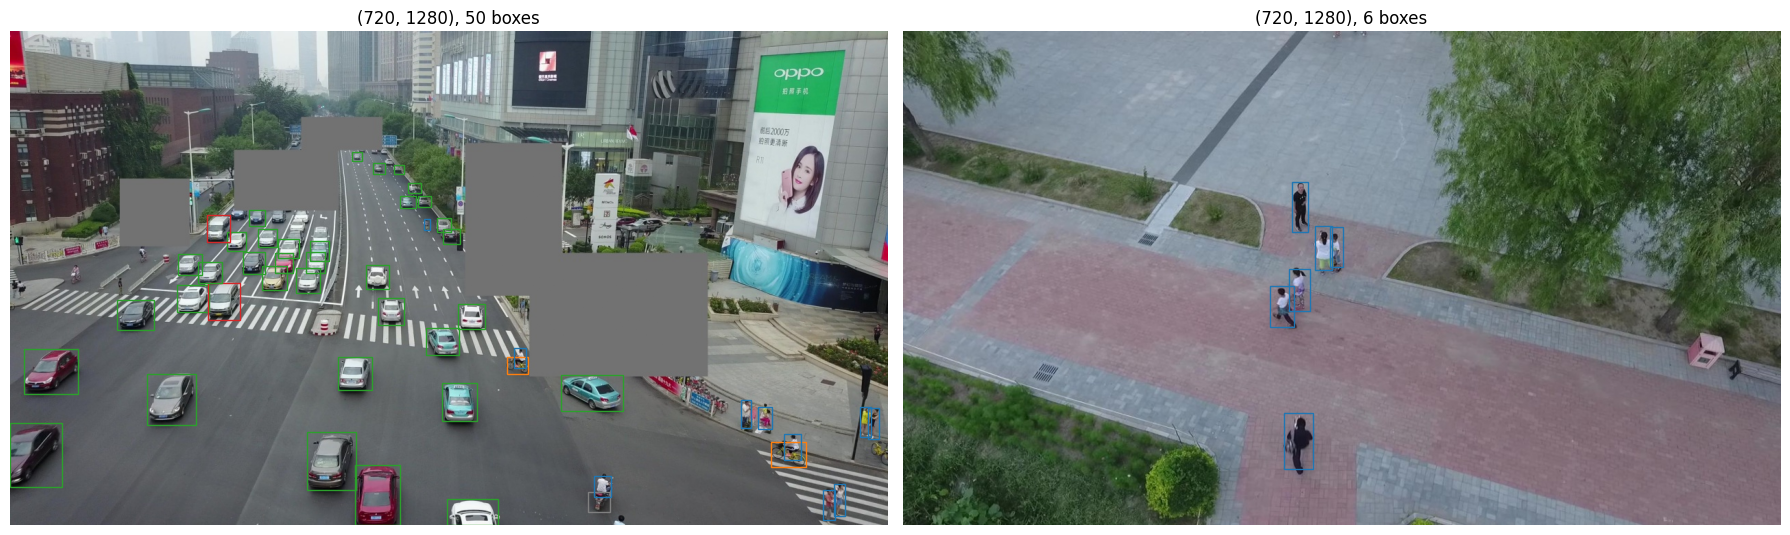

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
COLORS = plt.cm.tab10(range(8))

imgs, targets = next(iter(train_dl))
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, img, t in zip(axes, imgs, targets):
    ax.imshow(img.permute(1, 2, 0))
    for (x1, y1, x2, y2), l in zip(t['boxes'].tolist(), t['labels'].tolist()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1, ec=COLORS[l - 1]))
    ax.set_title(f'{tuple(img.shape[1:])}, {len(t["boxes"])} boxes'); ax.set_axis_off()
plt.tight_layout(); plt.show()

на лівому кадрі є видимі люди й машини без боксів. частина об'єктів не розмічена. Модель їх знаходитиме, а метрика рахуватиме як помилки - кандидат для аналізу помилок (крок 8).

## Model and training setup
Faster R-CNN with a ResNet-50-FPN backbone (torchvision `fasterrcnn_resnet50_fpn_v2`), initialised from COCO-pretrained weights; the box predictor is replaced with a new head for 8 classes + background.
Settings changed from the torchvision defaults, based on the EDA:
- `min_size=720, max_size=1280`: frames are already 1280×720, so the model does not rescale them.
- `box_detections_per_img=300`: up to 180 objects per frame (default is only 100).
- `box_score_thresh=0.001`: keep low-confidence detections so mAP is computed correctly.

`build_model(**overrides)` lets each experiment change one parameter while everything else stays the same.

In [9]:
import time, torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

DEVICE = 'cuda'
BASE = dict(
    min_size=720, max_size=1280,                                # кадри вже 1280×720
    box_detections_per_img=300,                                 # до 180 об'єктів на кадр (EDA)
    box_score_thresh=0.001,                                     # низький поріг для коректного mAP
    rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=1000,   # к-сть proposals (default)
    box_batch_size_per_image=512, box_positive_fraction=0.25,      # RoI sampling (default)
)

def build_model(**overrides):
    """Faster R-CNN з COCO-вагами; overrides змінюють окремі параметри для експериментів."""
    m = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT, **{**BASE, **overrides})
    in_f = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_f, len(CLASSES) + 1)   # 8 класів + фон
    return m.to(DEVICE)

#### Speed and memory check
A few training iterations to verify that the pipeline runs, fits into GPU memory, and to estimate the time per epoch.

In [ ]:
model = build_model()
opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.001, momentum=0.9, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')
model.train()
it = iter(train_dl)
for i in range(12):
    imgs, tg = next(it)
    imgs = [x.to(DEVICE) for x in imgs]
    tg = [{k: v.to(DEVICE) for k, v in t.items()} for t in tg]
    with torch.autocast('cuda', dtype=torch.float16):          # mixed precision: швидше і менше пам'яті
        losses = model(imgs, tg)
    loss = sum(losses.values())
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    if i == 1:                                                  # перші 2 ітерації — розігрів
        torch.cuda.synchronize(); t0 = time.time()
torch.cuda.synchronize()
sec_it = (time.time() - t0) / 10

print('losses:', {k: round(v.item(), 3) for k, v in losses.items()})
print(f'{sec_it:.2f} s/iter -> одна епоха ≈ {sec_it * len(train_dl) / 60:.0f} хв')
print(f'пік пам\'яті GPU: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB')
del model, opt; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 106MB/s]


losses: {'loss_classifier': 0.834, 'loss_box_reg': 0.74, 'loss_objectness': 0.172, 'loss_rpn_box_reg': 0.174}
0.63 s/iter -> одна епоха ≈ 13 хв
пік пам'яті GPU: 4.8 GB


## Evaluation
Predictions are made on the original val frames (every 5th frame, 571 frames, not masked). Metrics are computed with pycocotools (`maxDets=500`); detections inside ignored regions are not penalised thanks to `iscrowd=1` in the ground truth. The same evaluation is used for every model.

In [10]:
import json, contextlib, io, pandas as pd
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

with contextlib.redirect_stdout(io.StringIO()):
    gt = COCO(str(ROOT / 'val/annotations_coco.json'))
imgs_va = pd.DataFrame(gt.dataset['images']).rename(columns={'id': 'image_id'})
val_sub = imgs_va.sort_values(['video', 'frame_id'])
val_sub = val_sub[val_sub.groupby('video').cumcount() % 5 == 0]       # той самий кожен 5-й кадр
print('val frames for evaluation:', len(val_sub))

@torch.no_grad()
def predict(model, df, split='val', bs=4):
    """Передбачення на оригінальних кадрах -> список у COCO-форматі (bbox = [x, y, w, h] у пікселях)."""
    model.eval(); out = []
    for i in range(0, len(df), bs):
        rows = df.iloc[i:i + bs]
        ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / split / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
               for f in rows.file_name]
        with torch.autocast('cuda', dtype=torch.float16):
            res = model(ims)
        for iid, r in zip(rows.image_id, res):
            b = r['boxes'].float().cpu().numpy(); b[:, 2:] -= b[:, :2]      # xyxy -> xywh
            for box, s, l in zip(b, r['scores'].float().cpu().numpy(), r['labels'].cpu().numpy()):
                out.append({'image_id': int(iid), 'category_id': int(l),   # мітки 1..8 = COCO category_id
                            'bbox': [round(float(v), 2) for v in box], 'score': float(s)})
    return out

def evaluate(preds, img_ids):
    """COCO mAP + AP по класах."""
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(preds)
        E = COCOeval(gt, dt, 'bbox')
        E.params.imgIds = list(img_ids); E.params.maxDets = [1, 100, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    res = {'mAP': s[0], 'AP50': s[1], 'AP75': s[2], 'AP_small': s[3], 'AP_medium': s[4], 'AP_large': s[5]}
    prec = E.eval['precision']                                           # [IoU, recall, class, area, maxDets]
    for k, c in enumerate(CLASSES):
        p = prec[:, :, k, 0, -1]
        res[f'AP_{c}'] = float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    return res

val frames for evaluation: 571


## Training
Training protocol (the same for the baseline and every experiment):
- SGD, lr 0.005 (linear scaling rule: 0.02 for batch 16 -> 0.005 for batch 4), momentum 0.9, weight decay 1e-4
- linear warm-up for the first 300 iterations, lr × 0.1 after epoch 5
- 6 epochs, batch size 4, mixed precision (AMP), seed 42
- val mAP after every epoch; checkpoint and history are saved to Google Drive after every epoch, so a run can be resumed if Colab disconnects.

In [11]:
CKPT = Path('/content/drive/MyDrive/hw2_runs')
CKPT.mkdir(exist_ok=True)
TRAIN_CFG = dict(epochs=6, batch_size=4, lr=0.005, momentum=0.9, weight_decay=1e-4,
                 warmup_iters=300, lr_drop_epoch=5, amp=True, seed=SEED)


def save_ckpt(path, model, opt, sched, scaler, ep, hist):
    state = dict(model=model.state_dict(), opt=opt.state_dict(),
                 sched=sched.state_dict(), scaler=scaler.state_dict(),
                 epoch=ep, hist=hist)
    torch.save(state, path)


def train_run(name, build_fn=None, patch=None, smoke=False, **model_kw):
    """Train with the shared protocol TRAIN_CFG.
    patch(model, on): loss modification; smoke=True: only 20 iterations."""
    build_fn = build_fn or build_model
    seed_everything()
    g.manual_seed(SEED)
    model = build_fn(**model_kw)
    if patch:
        patch(model, True)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=TRAIN_CFG['lr'], momentum=TRAIN_CFG['momentum'],
                          weight_decay=TRAIN_CFG['weight_decay'])
    n_it = len(train_dl)

    def lr_fn(it):
        warm = min(1, (it + 1) / TRAIN_CFG['warmup_iters'])
        drop = 0.1 if it >= TRAIN_CFG['lr_drop_epoch'] * n_it else 1
        return warm * drop

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)
    scaler = torch.amp.GradScaler('cuda')
    hist, start = [], 0
    ck = CKPT / f'{name}.pt'
    if ck.exists() and not smoke:
        s = torch.load(ck, weights_only=False)
        model.load_state_dict(s['model'])
        opt.load_state_dict(s['opt'])
        sched.load_state_dict(s['sched'])
        scaler.load_state_dict(s['scaler'])
        hist, start = s['hist'], s['epoch'] + 1
        print(f'resume {name} from epoch {start}')
    try:
        for ep in range(start, TRAIN_CFG['epochs']):
            model.train()
            t0, run = time.time(), {}
            for i, (imgs, tg) in enumerate(train_dl):
                imgs = [x.to(DEVICE) for x in imgs]
                tg = [{k: v.to(DEVICE) for k, v in t.items()} for t in tg]
                with torch.autocast('cuda', dtype=torch.float16):
                    losses = model(imgs, tg)
                loss = sum(losses.values())
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                sched.step()
                for k, v in losses.items():
                    run[k] = run.get(k, 0) + v.item()
                if smoke and i % 5 == 0:
                    print('  smoke iter', i, {k: round(v.item(), 3) for k, v in losses.items()})
                if smoke and i == 20:
                    print('smoke test OK')
                    return model, None
                if i % 300 == 0:
                    print(f'  epoch {ep} iter {i}/{n_it} loss {loss.item():.3f}')
            train_min = (time.time() - t0) / 60
            m = evaluate(predict(model, val_sub), val_sub.image_id)
            rec = {'epoch': ep, 'train_min': train_min}
            rec.update({k: v / n_it for k, v in run.items()})
            rec.update(m)
            hist.append(rec)
            print(f"epoch {ep}: mAP {m['mAP']:.4f} | AP50 {m['AP50']:.4f} | "
                  f"AP_small {m['AP_small']:.4f} | {train_min:.0f} min")
            save_ckpt(ck, model, opt, sched, scaler, ep, hist)
            json.dump(hist, open(CKPT / f'{name}_hist.json', 'w'), indent=1)
    finally:
        if patch:
            patch(model, False)
    return model, pd.DataFrame(hist)

print('train_run ready')

train_run ready


### Baseline
Faster R-CNN with the default torchvision settings for RPN proposals (2000 train / 1000 test) and RoI sampling (512 RoIs per image, 25% positives).

In [ ]:
model_base, hist_base = train_run('frcnn_baseline')
hist_base[['epoch', 'mAP', 'AP50', 'AP_small', 'loss_classifier', 'loss_box_reg']].round(4)

resume frcnn_baseline from epoch 6


,epoch,mAP,AP50,AP_small,loss_classifier,loss_box_reg
0,0,0.2090,0.4386,0.0974,0.3456,0.4221
1,1,0.2131,0.4364,0.1068,0.2202,0.3476
2,2,0.2168,0.4517,0.1036,0.1932,0.3246
3,3,0.2279,0.4608,0.1011,0.1764,0.3096
4,4,0.2226,0.4521,0.1042,0.1642,0.2951
5,5,0.2303,0.4530,0.1162,0.1439,0.2678


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import json
print(json.load(open('/content/drive/MyDrive/hw2_runs/frcnn_baseline_hist.json'))[-1]['epoch'], '— остання збережена епоха')

Mounted at /content/drive
3 — остання збережена епоха


1. mAP almost doesnt grow after 1st epoch(0.209-> -0.23)
2. AP50 - is almost the sam (0.439->0.453)
-> model overfit with time, but it wont help on val dataset -> no sense in increasing number of epoch
3. AP_small is twice smaller than mAP-> bad on small objects
4. AP50 almost twice bigger than mAP -> model is not bad at finding objects, but frames are not accurate for higher threshholds IoU. For small objects shift by 2–3 px decreases IoU very much. -> experiment with box regression loss.

### Baseline results
Final metrics after 6 epochs, AP per class, and inference speed (batch 1, 1280×720 input, mixed precision; model forward only, image decoding excluded).

In [ ]:
@torch.no_grad()
def measure_speed(model, df, n=50, warmup=5):
    """Середній час інференсу на кадр (лише forward моделі, без читання картинки)."""
    model.eval()
    ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / 'val' / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
           for f in df.file_name.iloc[:n]]
    times = []
    for i, im in enumerate(ims):
        torch.cuda.synchronize(); t0 = time.time()
        with torch.autocast('cuda', dtype=torch.float16):
            model([im])
        torch.cuda.synchronize()
        if i >= warmup:
            times.append(time.time() - t0)
    ms = np.mean(times) * 1000
    return {'ms_per_img': round(ms, 1), 'FPS': round(1000 / ms, 1)}

speed_base = measure_speed(model_base, val_sub)
final_base = hist_base.iloc[-1]
print('Speed:', speed_base)
print(final_base[['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']].round(4).to_dict())
print('\nAP per class:')
print(final_base[[f'AP_{c}' for c in CLASSES]].round(4).to_dict())

Speed: {'ms_per_img': np.float64(80.2), 'FPS': np.float64(12.5)}
{'mAP': 0.2303, 'AP50': 0.453, 'AP75': 0.2073, 'AP_small': 0.1162, 'AP_medium': 0.2161, 'AP_large': 0.4014}

AP per class:
{'AP_person': 0.2639, 'AP_bicycle': 0.2154, 'AP_car': 0.3821, 'AP_van': 0.2509, 'AP_truck': 0.3022, 'AP_tricycle': 0.2356, 'AP_bus': 0.0783, 'AP_motor': 0.114}


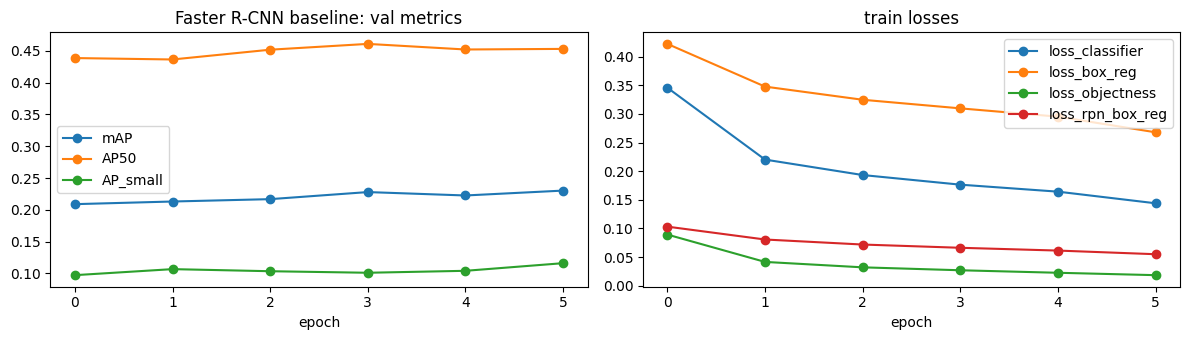

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
hist_base.plot(x='epoch', y=['mAP', 'AP50', 'AP_small'], marker='o', ax=ax[0]); ax[0].set_title('Faster R-CNN baseline: val metrics')
hist_base.plot(x='epoch', y=['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'], marker='o', ax=ax[1])
ax[1].set_title('train losses')
plt.tight_layout(); plt.savefig('frcnn_baseline_curves.png', dpi=120); plt.show()

## Experiments
Training function updated: `patch` allows modifying the loss during training (used in Experiment 2), `smoke=True` runs only 20 iterations to check that a new setup works before a full run. The training protocol is unchanged.

### Experiment 1a: number of RPN proposals at test time (no retraining)
Scenes contain up to 180 objects per frame (EDA), while RPN keeps only 1000 proposals at test time. A cheap sweep on the trained baseline shows whether more proposals help and what they cost in speed.

In [ ]:
rows = []
for n in [300, 1000, 2000, 3000]:
    model_base.rpn._pre_nms_top_n['testing'] = n
    model_base.rpn._post_nms_top_n['testing'] = n
    m = evaluate(predict(model_base, val_sub), val_sub.image_id)
    rows.append({'test proposals': n, **{k: round(m[k], 4) for k in ['mAP', 'AP50', 'AP_small']},
                 **measure_speed(model_base, val_sub)})
model_base.rpn._pre_nms_top_n['testing'] = model_base.rpn._post_nms_top_n['testing'] = 1000   # повертаємо default
sweep = pd.DataFrame(rows); sweep.to_csv(CKPT / 'frcnn_sweep_proposals.csv', index=False); sweep

,test proposals,mAP,AP50,AP_small,ms_per_img,FPS
0,300,0.2086,0.3968,0.0978,57.3,17.5
1,1000,0.2303,0.4530,0.1162,74.2,13.5
2,2000,0.2319,0.4603,0.1203,95.2,10.5
3,3000,0.2294,0.4572,0.1239,115.8,8.6


### Experiment 1b: RoI sampling
The test-time sweep showed that the number of proposals is not the bottleneck beyond 1000. The second stage is trained on 512 RoIs per image with at most 25% positives (≤128), while dense frames contain up to 180 objects, so many objects are not sampled as positives in each step. RoIs per image are increased to 1024 with 50% positives (≤512).

In [ ]:
model_exp1, hist_exp1 = train_run('frcnn_exp1_roi_sampling',
                                  box_batch_size_per_image=1024, box_positive_fraction=0.5)
hist_exp1[['epoch', 'mAP', 'AP50', 'AP_small']].round(4)

  epoch 0 iter 0/1217 loss 3.429
  epoch 0 iter 300/1217 loss 0.981
  epoch 0 iter 600/1217 loss 0.696
  epoch 0 iter 900/1217 loss 0.936
  epoch 0 iter 1200/1217 loss 0.992
epoch 0: mAP 0.2133 | AP50 0.4471 | AP_small 0.1023 | 19 min
  epoch 1 iter 0/1217 loss 1.127
  epoch 1 iter 300/1217 loss 1.250
  epoch 1 iter 600/1217 loss 1.131
  epoch 1 iter 900/1217 loss 0.905
  epoch 1 iter 1200/1217 loss 0.751
epoch 1: mAP 0.2046 | AP50 0.4261 | AP_small 0.0976 | 19 min
  epoch 2 iter 0/1217 loss 0.935
  epoch 2 iter 300/1217 loss 1.028
  epoch 2 iter 600/1217 loss 0.512
  epoch 2 iter 900/1217 loss 0.657
  epoch 2 iter 1200/1217 loss 0.520
epoch 2: mAP 0.2103 | AP50 0.4313 | AP_small 0.0983 | 19 min
  epoch 3 iter 0/1217 loss 1.037
  epoch 3 iter 300/1217 loss 0.862
  epoch 3 iter 600/1217 loss 0.767
  epoch 3 iter 900/1217 loss 0.678
  epoch 3 iter 1200/1217 loss 0.834
epoch 3: mAP 0.2054 | AP50 0.4166 | AP_small 0.1104 | 19 min
  epoch 4 iter 0/1217 loss 0.581
  epoch 4 iter 300/1217 los

,epoch,mAP,AP50,AP_small
0,0,0.2133,0.4471,0.1023
1,1,0.2046,0.4261,0.0976
2,2,0.2103,0.4313,0.0983
3,3,0.2054,0.4166,0.1104
4,4,0.2081,0.4252,0.0912
5,5,0.2144,0.4359,0.0944


### Experiment 2: GIoU box regression loss in the RoI head
The baseline regresses box offsets with Smooth L1. AP50 (0.45) is about twice the mAP (0.23): objects are found but localised poorly, which hurts small objects most, since a shift of 2–3 px changes their IoU a lot. GIoU loss optimises the box overlap directly (Rezatofighi et al., 2019). The second-stage box loss is replaced with GIoU (weight 10, as in MMDetection's Faster R-CNN GIoU config); everything else is unchanged.

In [12]:
import torch.nn.functional as F
import torchvision.models.detection.roi_heads as rh
from torchvision.ops import generalized_box_iou_loss

_ORIG_FRCNN_LOSS = rh.fastrcnn_loss
GIOU_W = 10.0

def giou_patch(model, on=True):
    """Замінює Smooth L1 у RoI head на GIoU loss (on=True) або повертає оригінал (on=False)."""
    if not on:
        rh.fastrcnn_loss = _ORIG_FRCNN_LOSS
        return
    heads, stash = model.roi_heads, {}
    orig_select = heads.select_training_samples
    def select(proposals, targets):                      # запам'ятовуємо proposals, щоб декодувати рамки
        out = orig_select(proposals, targets)
        stash['proposals'] = out[0]
        return out
    heads.select_training_samples = select
    def loss(class_logits, box_regression, labels, regression_targets):
        labels = torch.cat(labels, 0)
        cls_loss = F.cross_entropy(class_logits, labels)
        pos = torch.where(labels > 0)[0]
        props = torch.cat(stash['proposals'], 0)[pos].float()
        reg = box_regression.reshape(class_logits.shape[0], -1, 4)[pos, labels[pos]].float()
        tgt = torch.cat(regression_targets, 0)[pos].float()
        pred_boxes = heads.box_coder.decode_single(reg, props)    # зсуви -> рамки [x1, y1, x2, y2]
        tgt_boxes = heads.box_coder.decode_single(tgt, props)
        box_loss = GIOU_W * generalized_box_iou_loss(pred_boxes, tgt_boxes, reduction='sum') / labels.numel()
        return cls_loss, box_loss
    rh.fastrcnn_loss = loss

_ = train_run('smoke_giou', patch=giou_patch, smoke=True)     # перевірка: має надрукувати losses і 'smoke test OK'

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 172MB/s]


  smoke iter 0 {'loss_classifier': 2.431, 'loss_box_reg': 0.693, 'loss_objectness': 0.405, 'loss_rpn_box_reg': 0.145}
  epoch 0 iter 0/1217 loss 3.674
  smoke iter 5 {'loss_classifier': 2.375, 'loss_box_reg': 0.716, 'loss_objectness': 1.014, 'loss_rpn_box_reg': 0.213}
  smoke iter 10 {'loss_classifier': 2.063, 'loss_box_reg': 0.695, 'loss_objectness': 0.945, 'loss_rpn_box_reg': 0.274}
  smoke iter 15 {'loss_classifier': 1.555, 'loss_box_reg': 0.794, 'loss_objectness': 1.045, 'loss_rpn_box_reg': 0.186}
  smoke iter 20 {'loss_classifier': 1.048, 'loss_box_reg': 0.804, 'loss_objectness': 0.114, 'loss_rpn_box_reg': 0.125}
smoke test OK


In [13]:
model_exp2, hist_exp2 = train_run('frcnn_exp2_giou', patch=giou_patch)
hist_exp2[['epoch', 'mAP', 'AP50', 'AP75', 'AP_small', 'loss_box_reg']].round(4)


resume frcnn_exp2_giou from epoch 6


,epoch,mAP,AP50,AP75,AP_small,loss_box_reg
0,0,0.2073,0.4354,0.1709,0.1024,0.5542
1,1,0.2115,0.4354,0.1820,0.0956,0.4829
2,2,0.1990,0.4221,0.1625,0.0911,0.4613
3,3,0.2126,0.4341,0.1787,0.1086,0.4454
4,4,0.2140,0.4326,0.1910,0.0926,0.4312
5,5,0.2158,0.4360,0.1885,0.1027,0.4024


Comparison fastercnn

In [14]:
model_base, hist_base = train_run('frcnn_baseline')
model_exp1, hist_exp1 = train_run('frcnn_exp1_roi_sampling', box_batch_size_per_image=1024, box_positive_fraction=0.5)
model_exp2, hist_exp2 = train_run('frcnn_exp2_giou', patch=giou_patch)

resume frcnn_baseline from epoch 6
resume frcnn_exp1_roi_sampling from epoch 6
resume frcnn_exp2_giou from epoch 6


### What each stage contributes
For 150 val frames we compare (1) proposal recall: the share of ground-truth objects covered by at least one RPN proposal with IoU ≥ 0.5 (class-agnostic), and (2) final recall: the share covered by a final detection of the correct class (IoU ≥ 0.5, score ≥ 0.05), broken down by object size.

In [15]:
def iou_xyxy(a, b):
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = iw * ih
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

anns_va = pd.DataFrame(gt.dataset['annotations'])
anns_va[['x', 'y', 'w', 'h']] = pd.DataFrame(anns_va.bbox.tolist(), index=anns_va.index)

@torch.no_grad()
def stage_recall(model, df, n=150):
    model.eval(); rows = []
    for f, iid in zip(df.file_name.iloc[:n], df.image_id.iloc[:n]):
        im = TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / 'val' / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            images, _ = model.transform([im])
            feats = model.backbone(images.tensors)
            props, _ = model.rpn(images, feats)                                  # стадія 1
            dets = model.roi_heads(feats, props, images.image_sizes)[0][0]       # стадія 2
        H, W = im.shape[1:]; h, w = images.image_sizes[0]
        s = np.array([W / w, H / h, W / w, H / h])                                # назад в оригінальні пікселі
        P = props[0].float().cpu().numpy() * s
        keep = dets['scores'].float().cpu().numpy() >= 0.05
        D = dets['boxes'].float().cpu().numpy()[keep] * s
        DL = dets['labels'].cpu().numpy()[keep]
        G = anns_va[(anns_va.image_id == iid) & (anns_va.iscrowd == 0)]
        if not len(G):
            continue
        g = np.c_[G.x, G.y, G.x + G.w, G.y + G.h]
        prop_hit = iou_xyxy(g, P).max(1) >= 0.5 if len(P) else np.zeros(len(g), bool)
        if len(D):
            iou_d = iou_xyxy(g, D) * (G.category_id.values[:, None] == DL[None, :])
            det_hit = iou_d.max(1) >= 0.5
        else:
            det_hit = np.zeros(len(g), bool)
        for sz, ph, dh in zip(np.sqrt(G.w * G.h), prop_hit, det_hit):
            rows.append({'size': 'small' if sz < 32 else 'medium' if sz < 96 else 'large',
                         'proposal recall': ph, 'final recall': dh})
    r = pd.DataFrame(rows)
    out = r.groupby('size')[['proposal recall', 'final recall']].mean()
    out.loc['all'] = r[['proposal recall', 'final recall']].mean()
    return (out * 100).round(1)

stage_recall(model_base, val_sub)

,proposal recall,final recall
size,,
large,99.5,86.3
medium,88.2,79.4
small,78.0,67.9
all,87.2,77.7


In [16]:
rows = []
for name in ['frcnn_baseline', 'frcnn_exp1_roi_sampling', 'frcnn_exp2_giou']:
    h = json.load(open(CKPT / f'{name}_hist.json'))[-1]
    rows.append({'run': name, **{k: round(h[k], 4) for k in ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']}})
pd.DataFrame(rows)

,run,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,frcnn_baseline,0.2303,0.4530,0.2073,0.1162,0.2161,0.4014
1,frcnn_exp1_roi_sampling,0.2144,0.4359,0.1845,0.0944,0.2054,0.3807
2,frcnn_exp2_giou,0.2158,0.4360,0.1885,0.1027,0.2039,0.3936


### Failure analysis
Baseline detections with score ≥ 0.3 are matched to the ground truth (IoU ≥ 0.5, greedy by score). Each missed object and each false detection gets an error type: wrong class, poor localization (same class, 0.1 ≤ IoU < 0.5), duplicate, background (no object nearby). Detections inside ignored regions are excluded. Missed objects are broken down by size and occlusion, then representative frames are shown.

In [17]:
P = pd.DataFrame(predict(model_base, val_sub))
P[['x', 'y', 'w', 'h']] = pd.DataFrame(P.bbox.tolist(), index=P.index)
P = P[P.score >= 0.3]
xyxy = lambda df: np.c_[df.x, df.y, df.x + df.w, df.y + df.h]

gt_rows, dt_rows = [], []
for iid in val_sub.image_id:
    G = anns_va[(anns_va.image_id == iid) & (anns_va.iscrowd == 0)]
    I = anns_va[(anns_va.image_id == iid) & (anns_va.iscrowd == 1)].drop_duplicates(['x', 'y', 'w', 'h'])
    D = P[P.image_id == iid].sort_values('score', ascending=False)
    g, d = xyxy(G), xyxy(D)
    iou = iou_xyxy(d, g) if len(d) and len(g) else np.zeros((len(d), len(g)))
    same = D.category_id.values[:, None] == G.category_id.values[None, :]
    used = np.zeros(len(g), bool)
    for k, row in enumerate(D.itertuples()):
        cand = np.where(same[k] & ~used & (iou[k] >= 0.5))[0]
        gt_cls = None
        if len(cand):
            used[cand[np.argmax(iou[k, cand])]] = True; t = 'TP'
        elif len(g) and (same[k] & (iou[k] >= 0.5)).any():
            t = 'duplicate'
        elif len(g) and (~same[k] & (iou[k] >= 0.5)).any():
            t = 'wrong class'; gt_cls = G.category_id.values[np.argmax(iou[k] * ~same[k])]
        elif len(g) and (same[k] & (iou[k] >= 0.1)).any():
            t = 'poor localization'
        else:
            inside = 0
            if len(I):
                ib = xyxy(I)
                iw = np.clip(np.minimum(d[k, 2], ib[:, 2]) - np.maximum(d[k, 0], ib[:, 0]), 0, None)
                ih = np.clip(np.minimum(d[k, 3], ib[:, 3]) - np.maximum(d[k, 1], ib[:, 1]), 0, None)
                inside = (iw * ih).max() / (row.w * row.h)
            t = 'in ignored region' if inside >= 0.5 else 'background'
        dt_rows.append({'image_id': iid, 'cls': CLASSES[row.category_id - 1], 'score': row.score, 'type': t,
                        'gt_cls': CLASSES[gt_cls - 1] if gt_cls else None, 'x': row.x, 'y': row.y, 'w': row.w, 'h': row.h})
    for j, r in enumerate(G.itertuples()):
        if used[j]:
            t = 'detected'
        elif len(d) and (~same[:, j] & (iou[:, j] >= 0.5)).any():
            t = 'missed: wrong class'
        elif len(d) and (same[:, j] & (iou[:, j] >= 0.1)).any():
            t = 'missed: poor localization'
        else:
            t = 'missed: no detection'
        sz = np.sqrt(r.w * r.h)
        gt_rows.append({'image_id': iid, 'cls': CLASSES[r.category_id - 1], 'type': t, 'occlusion': r.occlusion,
                        'size': 'small' if sz < 32 else 'medium' if sz < 96 else 'large',
                        'x': r.x, 'y': r.y, 'w': r.w, 'h': r.h})
GT_E, DT_E = pd.DataFrame(gt_rows), pd.DataFrame(dt_rows)

print('Detections (score >= 0.3) by type, %:\n', (DT_E.type.value_counts(normalize=True) * 100).round(1))
print('\nGround-truth objects by outcome and size, %:\n',
      (pd.crosstab(GT_E.type, GT_E['size'], normalize='columns') * 100).round(1))
print('\nMissed (no detection) by occlusion, %:\n',
      (GT_E.groupby('occlusion')['type'].apply(lambda s: (s == 'missed: no detection').mean()) * 100).round(1))
print('\nClass confusions (predicted -> true):\n',
      pd.crosstab(DT_E.loc[DT_E.type == 'wrong class', 'cls'], DT_E.loc[DT_E.type == 'wrong class', 'gt_cls']))

Detections (score >= 0.3) by type, %:
 type
TP                   56.3
background           18.2
wrong class          10.2
in ignored region     8.7
poor localization     6.1
duplicate             0.4
Name: proportion, dtype: float64

Ground-truth objects by outcome and size, %:
 size                       large  medium  small
type                                           
detected                    83.3    61.3   42.2
missed: no detection         5.2    22.0   36.9
missed: poor localization    1.4     9.1   14.3
missed: wrong class         10.0     7.6    6.6

Missed (no detection) by occlusion, %:
 occlusion
0.0    13.3
1.0    24.7
2.0    68.8
Name: type, dtype: float64

Class confusions (predicted -> true):
 gt_cls    bicycle  bus  car  motor  person  tricycle  truck  van
cls                                                             
bicycle         0    0    0    120      33        16      0    0
bus             0    0    1      0       0         1      0   32
car             0 

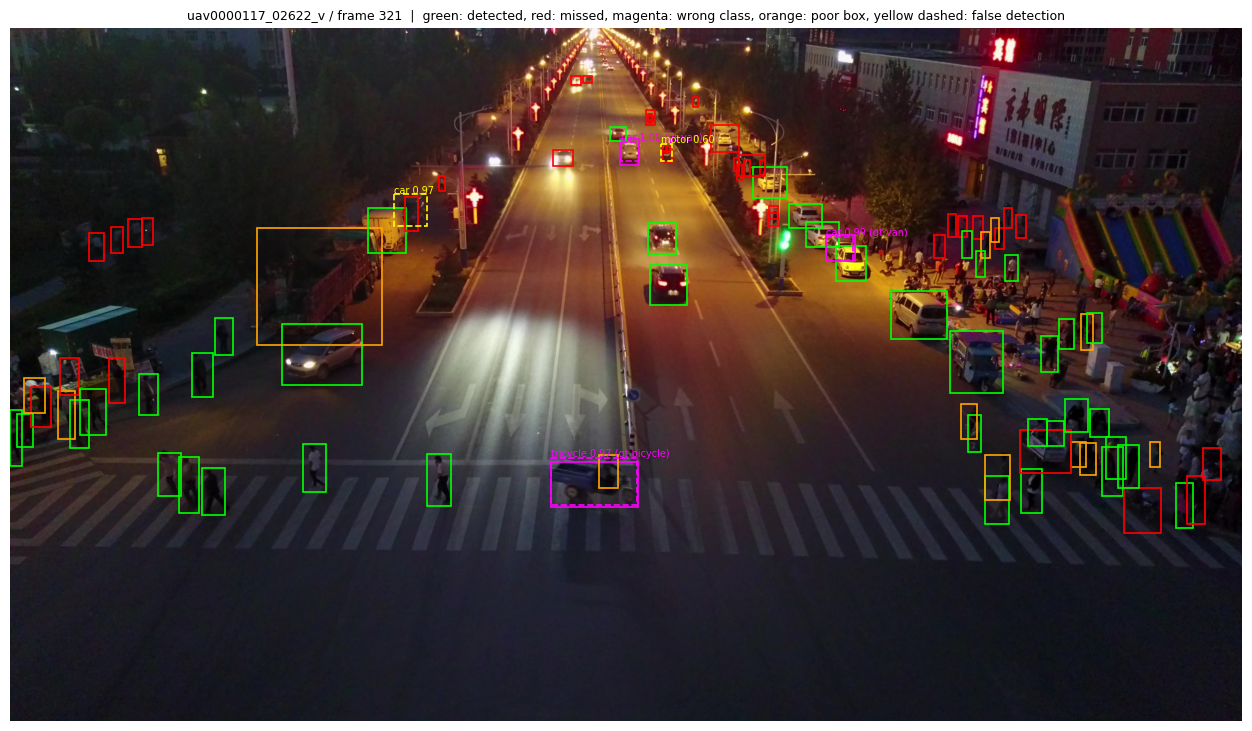

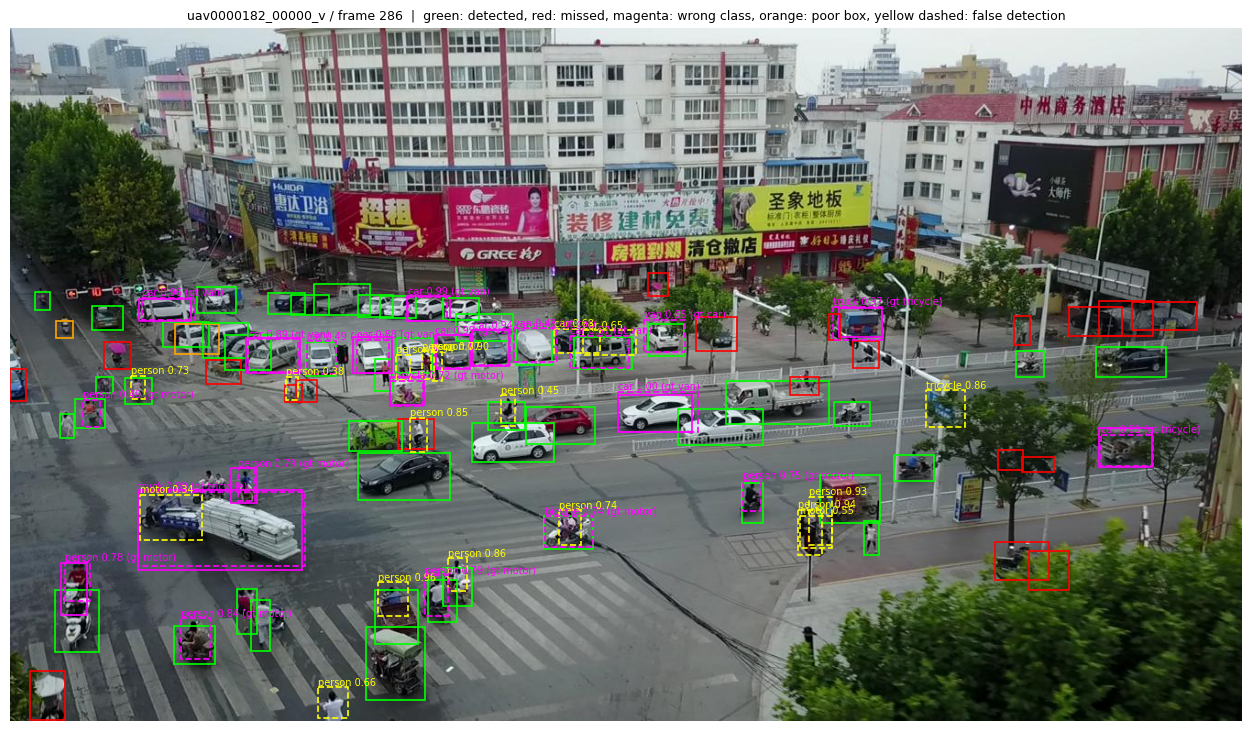

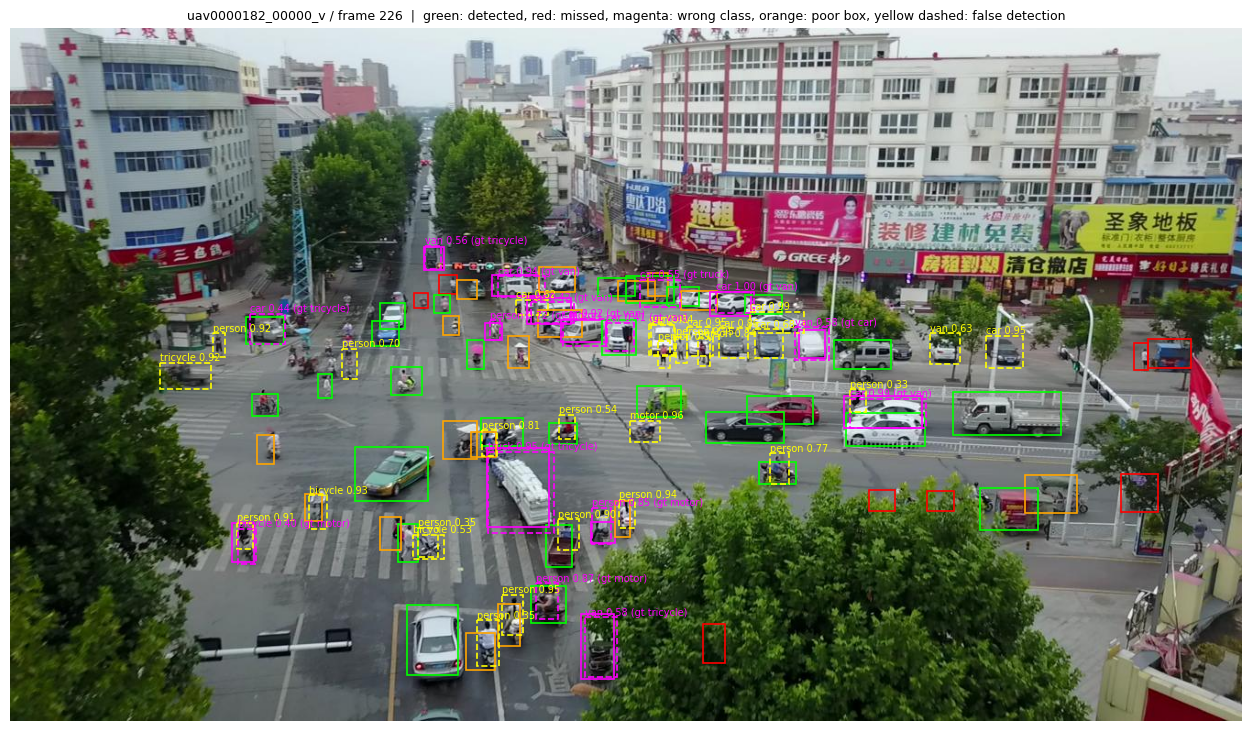

In [24]:
COLORS_E = {'detected': 'lime', 'missed: no detection': 'red', 'missed: wrong class': 'magenta',
            'missed: poor localization': 'orange', 'background': 'yellow', 'wrong class': 'magenta'}

def show_errors(iid, ax=None, zoom=None):
    info = val_sub[val_sub.image_id == iid].iloc[0]
    ax = ax or plt.subplots(figsize=(16, 9))[1]
    ax.imshow(cv2.cvtColor(cv2.imread(str(ROOT / 'val' / info.file_name)), cv2.COLOR_BGR2RGB))
    for r in GT_E[GT_E.image_id == iid].itertuples():
        ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, lw=1.2, ec=COLORS_E[r.type]))
    for r in DT_E[(DT_E.image_id == iid) & DT_E.type.isin(['background', 'wrong class'])].itertuples():
        ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, lw=1.2, ls='--', ec=COLORS_E[r.type]))
        ax.text(r.x, r.y - 2, f'{r.cls} {r.score:.2f}' + (f' (gt {r.gt_cls})' if r.gt_cls else ''),
                color=COLORS_E[r.type], fontsize=7)
    if zoom:
        x, y, w, h = zoom; ax.set_xlim(x, x + w); ax.set_ylim(y + h, y)
    ax.set_title(f'{info.video} / frame {info.frame_id}  |  green: detected, red: missed, '
                 f'magenta: wrong class, orange: poor box, yellow dashed: false detection', fontsize=9)
    ax.set_axis_off()

# кадри з найбільшою к-стю помилок кожного типу
worst = lambda df, t: df[df.type == t].image_id.value_counts().index[0]
for t, df in [('missed: no detection', GT_E), ('wrong class', DT_E), ('background', DT_E)]:
    show_errors(worst(df, t)); plt.savefig(f'failure_{t.split(":")[-1].strip().replace(" ", "_")}.png', dpi=120); plt.show()

submition

In [ ]:
test = pd.read_csv(ROOT / 'test_images.csv')

@torch.no_grad()
def predict_test(model, test, bs=4, max_det=500):
    model.eval(); rows = []
    for i in range(0, len(test), bs):
        chunk = test.iloc[i:i + bs]
        ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
               for f in chunk.file_name]
        with torch.autocast('cuda', dtype=torch.float16):
            res = model(ims)
        for iid, r in zip(chunk.image_id, res):
            b = r['boxes'].float().cpu().numpy(); b[:, 2:] -= b[:, :2]       # xyxy -> xywh
            s = r['scores'].float().cpu().numpy()
            l = r['labels'].cpu().numpy() - 1                                # 1..8 -> 0..7
            order = np.argsort(-s)[:max_det]
            rows.append((iid, ' '.join(f'{l[j]} {s[j]:.4f} {b[j, 0]:.1f} {b[j, 1]:.1f} {b[j, 2]:.1f} {b[j, 3]:.1f}'
                                       for j in order)))
    return pd.DataFrame(rows, columns=['image_id', 'PredictionString'])

sub = predict_test(model_base, test)
assert len(sub) == len(test) and sub.image_id.tolist() == test.image_id.tolist()
sub.to_csv('sub_frcnn_baseline.csv', index=False)
!cp sub_frcnn_baseline.csv /content/drive/MyDrive/hw2_runs/
print(sub.head(3))

In [ ]:
!kaggle competitions submit -c multiple-object-video-detection-hw-2-ucu-ai-2026 -f sub_frcnn_baseline.csv -m "Faster R-CNN baseline, 6 epochs, val mAP 0.230"

100% 20.3M/20.3M [00:00<00:00, 23.7MB/s]
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

In [ ]:
  !kaggle competitions submissions -c multiple-object-video-detection-hw-2-ucu-ai-2026

sub from drive

In [26]:
import pandas as pd

def shrink(s, thr=0.05, max_det=150):
    """Залишає детекції зі score >= thr, не більше max_det на кадр."""
    if not isinstance(s, str) or not s:
        return ''
    a = s.split()
    dets = [a[i:i + 6] for i in range(0, len(a), 6)]
    dets = [d for d in dets if float(d[1]) >= thr][:max_det]
    return ' '.join(' '.join(d) for d in dets)

sub = pd.read_csv('/content/drive/MyDrive/hw2_runs/sub_frcnn_baseline.csv')
sub['PredictionString'] = sub['PredictionString'].map(shrink)
sub.to_csv('sub_frcnn_baseline_small.csv', index=False)

test = pd.read_csv(ROOT / 'test_images.csv')
print('рядків:', len(sub), '| у test:', len(test), '| ті самі image_id:', set(sub.image_id) == set(test.image_id))
print('детекцій на кадр (середнє):', sub.PredictionString.fillna('').str.split().str.len().mean() / 6)
!ls -lh /content/drive/MyDrive/hw2_runs/sub_frcnn_baseline.csv sub_frcnn_baseline_small.csv

рядків: 3811 | у test: 3811 | ті самі image_id: True
детекцій на кадр (середнє): 72.8236683285227
-rw------- 1 root root  21M Nov  9 15:56 /content/drive/MyDrive/hw2_runs/sub_frcnn_baseline.csv
-rw-r--r-- 1 root root 8.4M Nov 10 06:47 sub_frcnn_baseline_small.csv


In [27]:
!kaggle competitions submit -c multiple-object-video-detection-hw-2-ucu-ai-2026 -f sub_frcnn_baseline_small.csv -m "Faster R-CNN baseline, score>=0.05, max 150 det"

100% 8.31M/8.31M [00:00<00:00, 30.8MB/s]
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026

baseline with new resolution

In [28]:
for ms, mx in [(720, 1280), (900, 1600), (1080, 1920)]:
    model_base.transform.min_size = (ms,); model_base.transform.max_size = mx
    m = evaluate(predict(model_base, val_sub), val_sub.image_id)
    print(f'{ms}x{mx}: mAP {m["mAP"]:.4f} | AP50 {m["AP50"]:.4f} | AP_small {m["AP_small"]:.4f}')
model_base.transform.min_size = (720,); model_base.transform.max_size = 1280      # повертаємо як було

720x1280: mAP 0.2303 | AP50 0.4530 | AP_small 0.1162
900x1600: mAP 0.2311 | AP50 0.4549 | AP_small 0.1236
1080x1920: mAP 0.2239 | AP50 0.4546 | AP_small 0.1389
